**Human Movement Intelligence | Biomechanical Load Estimation | Presented by: Reza Saadatyar (2026)**

**06 | Deep Temporal Regression and Biomechanical Peak Prediction**

![Essex temporal regression study, seven source wearable IMUs, native FE alignment, participant-disjoint model development and reserved Test](../../images/06_consolidated_workflow.svg)

**Research question:** Can compact temporal neural networks improve prediction of original first (`e1`) and third (`e3`) principal femoral-neck finite-element (FE) strain curves from the complete six-axis, seven-IMU trial signals, compared with the Stage 05 classical baselines, without compromising participant-level separation?

**Data foundation:** The checksum-verified [Essex Figshare v13 source](https://doi.org/10.6084/m9.figshare.30225739.v13), audited in [Notebook 04](04_governed_imu_fe_dataset_and_participant_splits.ipynb) and benchmarked in [Notebook 05](05_classical_regression_baselines_and_participant_independent_validation.ipynb). All 1,729 source-eligible trials retain native `101×42` IMU and `11×2` FE targets. Only Training (29 people, 1,354 trials) and Validation (four people, 192 trials) enter this study. The four Test subjects (183 trials) remain reserved.

**Temporal alignment:** Convolutional features are computed at all 101 recorded IMU coordinates; a source-verified index map selects the **eleven exact original FE positions**. The models predict two strain values at each of these positions. No interpolation, upsampling or invented FE measurements are used.

**Fixed model comparison:** Temporal CNN versus residual dilated TCN, each trained with the same 35-epoch budget, fold-specific input/target standardisation, AdamW optimisation and predeclared waveform-plus-peak objective. Five previously saved GroupKFold assignments from Training are reused. Model selection uses Training out-of-fold subject-balanced MAE **only**; independent predetermined Validation provides diagnostic results, not selection.

**Scientific interpretation:** The published FE strain outputs are **unitless model-derived targets**, not direct clinical measurements. Peak magnitude and peak-index differences refer to the eleven original FE coordinates. Stage 05 Random Forest and Ridge results provide recorded context, but their prior inspection means the programme's Validation set is **not fully blind for cross-stage research decisions**. Do not claim independent external validation or prospective deployment.

**Recorded results:** All 11 code cells executed without recorded errors, and the Stage 06 Quality Gate is **PASSED** with 14 committed evidence files. **Dilated TCN** was selected using Training-only grouped CV (subject-balanced MAE **0.0008513**, versus **0.0009048** for Temporal CNN). Its four-participant Validation score was **0.0007151** (Temporal CNN: **0.0007517**). The Stage 05 Random Forest still has lower overall Validation waveform error (**0.0006771**), but Dilated TCN reduces peak-value error for both targets. No Test or independent external evaluation was performed.


**00. Colab Repository Setup**


In [1]:
# ======================== 00. Colab Repository Setup =========================

# -------------------------- 1. Repository Checkout ---------------------------
from pathlib import Path
import subprocess

repo_url = "https://github.com/RezaSaadatyar/human-movement-intelligence.git"
repo_path = Path("/content") / repo_url.rsplit("/", 1)[-1].removesuffix(".git")

if not repo_path.exists():
    subprocess.run(["git", "clone", "-q", repo_url, str(repo_path)], check=True)

# ---------------------------- 2. Open Repository -----------------------------
%cd {repo_path}


Repository up to date.
/content/human-movement-intelligence


**01. Imports and Research Environment**


In [2]:
# =================== 01. Imports and Research Environment ====================
# -------------------------- 1. Study Environment ----------------------------
from python_modules.core.colab_setup import setup_colab
root = setup_colab("biomechanical_load_estimation")

# -------------------------- 2. Standard Library -----------------------------
import hashlib
import json
from importlib.metadata import version
from pathlib import Path

# --------------------- 3. Scientific and Deep Learning ----------------------
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display
from core.plot_style import plot_style, save_figure
plot_style(font_family="DejaVu Sans", title_size=12.5,
    title_weight="normal", label_size=11.5, label_weight="normal",
    tick_size=11, legend_size=10, figure_dpi=100, figure_size=(9, 4))

# ------------------------ 4. Reusable Study Code ----------------------------
from core.output_download import download_outputs_from_colab
from essex_figshare import (
    ARTICLE_ID, ARTICLE_VERSION, ensure_pinned_matlab_archive,
    inspect_matlab_archive, extract_matlab_files,
)
from essex_numeric_recovery import check_record_registry
from essex_paired_dataset import (
    build_paired_arrays, paired_source_digest, save_ignored_cache,
)
from essex_regression_baselines import (
    regression_metrics, participant_metrics, subject_balanced_mae,
    trial_predictions,
)
from essex_temporal_regression import (
    MODEL_NAMES, check_temporal_arrays, fit_temporal_model,
)

# --------------------------- 5. Output Locations ----------------------------
study_dir = root / "biomechanical_load_estimation"
raw_dir = root / "data" / "raw" / "essex_femoral_neck_loading"
mat_dir = raw_dir / "matlab_records"
processed_dir = root / "data" / "processed" / "essex_femoral_neck_loading"
output_dir = study_dir / "output"
processed_dir.mkdir(parents=True, exist_ok=True)
output_dir.mkdir(parents=True, exist_ok=True)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Deep learning device:", device)
print("Stage 06 evidence directory:", output_dir)


Deep learning device: cpu
Stage 06 evidence directory: /content/human-movement-intelligence/biomechanical_load_estimation/output


**02. Pinned Upstream Evidence and Participant Protection**

The executed checks confirmed the Stage 04 and Stage 05 Quality Gates, source fingerprints and fixed participant-disjoint partitions before fitting. Earlier Random Forest results were read as a reference. The four reserved Test participants were not involved in model training, model choice or performance reporting.


In [3]:
# ================== 02. Pinned Stage 04 Evidence and Splits ===================
# -------------------------- 1. Load Saved Evidence --------------------------
paths04 = {
    "gate": output_dir / "04_dataset_and_split_quality_gate.json",
    "manifest": output_dir / "04_local_dataset_build_manifest.json",
    "trials": output_dir / "04_trial_split_assignments.csv",
    "subjects": output_dir / "04_subject_split_assignments.csv",
    "source": output_dir / "01_consolidated_source_and_trial_quality_gate.json",
    "registry": output_dir / "01_original_record_registry.csv",
    "mapping": output_dir / "03_original_time_coordinate_mapping.csv",
}
missing04 = [key for key, path in paths04.items() if not path.is_file()]
if missing04:
    raise FileNotFoundError("Missing committed upstream evidence: " +
                            ", ".join(missing04))
gate04 = json.loads(paths04["gate"].read_text(encoding="utf-8"))
manifest04 = json.loads(paths04["manifest"].read_text(encoding="utf-8"))
source01 = json.loads(paths04["source"].read_text(encoding="utf-8"))
assigned = pd.read_csv(paths04["trials"], dtype=str)
subjects04 = pd.read_csv(paths04["subjects"], dtype=str)
assert gate04["stage04_quality_gate"] == "PASSED"
assert gate04["source_article_id"] == ARTICLE_ID == 30225739
assert gate04["source_version"] == ARTICLE_VERSION == 13
assert gate04["original_sha256"] == source01["archive_sha256"]
assert gate04["original_sha256"] == manifest04["original_archive_sha256"]
assert gate04["canonical_pair_sha256"] == manifest04["canonical_pair_sha256"]
assert manifest04["feature_shape"] == [1729, 101, 42]
assert manifest04["target_shape"] == [1729, 11, 2]
assert gate04["original_source_empty_fe"] == 168
assert gate04["original_target_units_as_published"] == "unitless"

# ------------------------ 2. Freeze Participant Roles -----------------------
expected_splits = {"TRAIN": 1354, "VALIDATION": 192, "TEST": 183}
assert assigned["split"].value_counts().to_dict() == expected_splits
assert assigned["local_record_key"].is_unique
assert len(assigned) == 1729
assert subjects04["subject_id"].is_unique
assert subjects04["split"].value_counts().to_dict() == {
    "TRAIN": 29, "VALIDATION": 4, "TEST": 4,
    "EXCLUDED_NO_FE_TARGET": 3,
}
assert assigned.groupby("subject_id")["split"].nunique().eq(1).all()
assert assigned["split"].eq(
    assigned["subject_id"].map(subjects04.set_index("subject_id")["split"])
).all()
train_mask = assigned["split"].eq("TRAIN").to_numpy()
valid_mask = assigned["split"].eq("VALIDATION").to_numpy()
test_mask = assigned["split"].eq("TEST").to_numpy()
assert not np.any(train_mask & valid_mask)
assert not np.any(train_mask & test_mask)
assert not np.any(valid_mask & test_mask)
print("Frozen Training trials:", train_mask.sum())
print("Frozen Validation trials:", valid_mask.sum())
print("Reserved Test trials (no model access):", test_mask.sum())

# ---------------- 3. Read-Only Stage 05 Baseline Reference ------------------
path05 = output_dir / "05_regression_protocol_and_quality_gate.json"
base_cv_path = output_dir / "05_training_cv_model_summary.csv"
base_val_path = output_dir / "05_validation_model_metrics.csv"
fold_path = output_dir / "05_training_fold_registry.csv"
for item in (path05, base_cv_path, base_val_path, fold_path):
    if not item.is_file():
        raise FileNotFoundError(f"Missing completed Stage 05 evidence: {item}")
gate05 = json.loads(path05.read_text(encoding="utf-8"))
assert gate05["quality_gate"] == "PASSED"
assert gate05["stage04_canonical_pair_sha256"] == (
    gate04["canonical_pair_sha256"]
)
assert gate05["source_archive_sha256"] == gate04["original_sha256"]
assert gate05["train_group_cv_folds"] == 5
assert gate05["selected_by_training_cv"] == "Random Forest"
baseline_cv = pd.read_csv(base_cv_path)
baseline_val = pd.read_csv(base_val_path)
prior_cv_score = float(baseline_cv.loc[
    baseline_cv["model"].eq("Random Forest"), "subject_balanced_mae"
].iloc[0])
prior_validation_score = float(baseline_val.loc[
    baseline_val["model"].eq("Random Forest"),
    "subject_balanced_mae",
].iloc[0])
print("Previously recorded Stage 05 Training-CV RF score:",
      f"{prior_cv_score:.7f}")
print("Stage 05 Validation is comparison-only; no Test access.")

display(assigned.groupby("split").agg(
    trials=("local_record_key", "size"),
    participants=("subject_id", "nunique"),
))


Frozen Training trials: 1354
Frozen Validation trials: 192
Reserved Test trials (no model access): 183
Previously recorded Stage 05 Training-CV RF score: 0.0007950
Stage 05 Validation is comparison-only; no Test access.


,trials,participants
split,,
TEST,183,4
TRAIN,1354,29
VALIDATION,192,4


**03. Source-Verified Numerical Cache**

The recorded run downloaded and verified the pinned MATLAB archive, reconstructed the local Git-ignored paired cache and passed the original Stage 04 source-pair SHA256 verification. Only Training and Validation numerical arrays were copied into the regression models. Source integrity checking of the full cache did not constitute Test evaluation.


In [4]:
# ============== 03. Verified Cache and Source Reconstruction ================
# ------------------- 1. Pinned Original MATLAB Reader -----------------------
%pip -q install --only-binary=:all: --no-deps "mat-io==1.0.1"
from matio import load_from_mat
assert version("mat-io") == "1.0.1"

# --------------------- 2. Rebuild Cache Only If Missing ----------------------
cache_path = processed_dir / "essex_imu_fe_pairs_v13.npz"
if not cache_path.exists():
    archive, hashes = ensure_pinned_matlab_archive(raw_dir)
    assert hashes["sha256"] == source01["archive_sha256"]
    inventory = inspect_matlab_archive(archive, expected_mat_files=40)
    mat_files = extract_matlab_files(archive, mat_dir, inventory)
    assert len(mat_files) == 40
    registry = pd.read_csv(paths04["registry"], dtype={
        "local_record_key": str, "source_file": str,
        "subject_id": str, "task": str, "updated_trial_id": str,
        "fe_representation": str,
    })
    mapping = pd.read_csv(paths04["mapping"], dtype={
        "local_record_key": str, "imu_position_indices": str,
        "mapping_status": str,
    })
    check_record_registry(registry, source01)
    rebuilt, eligible, excluded = build_paired_arrays(
        load_from_mat, mat_dir, registry, mapping, source01,
    )
    assert len(eligible) == 1729 and len(excluded) == 168
    assert eligible["local_record_key"].tolist() == (
        assigned["local_record_key"].tolist()
    )
    assert paired_source_digest(rebuilt, assigned) == (
        gate04["canonical_pair_sha256"]
    )
    save_ignored_cache(cache_path, rebuilt, assigned)
    del rebuilt, eligible, excluded
    print("Source-verified local cache reconstructed.")
else:
    print("Using existing Stage 04 cache, subject to fingerprint verification.")

# ---------------------- 3. Verify Cached Source Identity --------------------
with np.load(cache_path, allow_pickle=False) as saved:
    assert set(saved.files) == {
        "X_full", "X_at_fe", "y_fe", "imu_positions", "record_keys"
    }
    assert saved["record_keys"].astype(str).tolist() == (
        assigned["local_record_key"].tolist()
    )
    # Original Test source values are included ONLY in this integrity digest;
    # no Test feature/target is supplied to any estimator or metric below.
    source_digest = paired_source_digest(
        {key: saved[key] for key in (
            "X_full", "X_at_fe", "y_fe", "imu_positions"
        )}, assigned,
    )
    assert source_digest == gate04["canonical_pair_sha256"]
    x_train_source = saved["X_full"][train_mask].copy()
    x_valid_source = saved["X_full"][valid_mask].copy()
    idx_train_source = saved["imu_positions"][train_mask].copy()
    idx_valid_source = saved["imu_positions"][valid_mask].copy()
    y_train_source = saved["y_fe"][train_mask].copy()
    y_valid_source = saved["y_fe"][valid_mask].copy()
assert x_train_source.shape == (1354, 101, 42)
assert x_valid_source.shape == (192, 101, 42)
assert y_train_source.shape == (1354, 11, 2)
assert y_valid_source.shape == (192, 11, 2)
assert idx_train_source.shape == (1354, 11)
assert idx_valid_source.shape == (192, 11)
check_temporal_arrays(x_train_source, idx_train_source, y_train_source)
check_temporal_arrays(x_valid_source, idx_valid_source, y_valid_source)
print("Canonical Stage 04 source fingerprint: VERIFIED")
print("Test observations used in modelling or diagnostics: NONE")


MATLAB.zip downloaded and verified: GitHub Release.


/usr/local/lib/python3.13/dist-packages/pandas/core/indexes/base.py:7588: FutureWarning: Dtype inference on a pandas object (Series, Index, ExtensionArray) is deprecated. The Index constructor will keep the original dtype in the future. Call `infer_objects` on the result to get the old behavior.
  return Index(sequences[0], name=names)


Source-verified local cache reconstructed.
Canonical Stage 04 source fingerprint: VERIFIED
Test observations used in modelling or diagnostics: NONE


**04. Frozen Training Fold Registry and Temporal Data Contract**

The 1,354 Training trials and **five participant-disjoint fold assignments** were reused exactly from Notebook 05. Training contained 29 participants; the independent diagnostic Validation partition contained four participants and 192 trials. Four further Test participants (183 trials) remained reserved. The input and target contracts were the original 101-by-42 IMU signal and 11-by-2 source-aligned FE output, without target interpolation.


In [5]:
# ================ 04. Native-Time Trial and Split Contract ==================
# ----------------------- 1. Fixed Trial Identities --------------------------
train_info = assigned.loc[train_mask].reset_index(drop=True)
valid_info = assigned.loc[valid_mask].reset_index(drop=True)
reserved_ids = set(assigned.loc[test_mask, "subject_id"])
train_ids = set(train_info["subject_id"])
valid_ids = set(valid_info["subject_id"])
assert not train_ids & valid_ids
assert not train_ids & reserved_ids
assert not valid_ids & reserved_ids
assert len(train_ids) == 29 and len(valid_ids) == 4
assert len(reserved_ids) == 4

# ---------------- 2. Reuse Stage 05 Participant GroupKFold ------------------
prior_folds = pd.read_csv(fold_path, dtype={
    "local_record_key": str, "subject_id": str, "task": str,
})
assert len(prior_folds) == len(train_info) == 1354
assert prior_folds["local_record_key"].is_unique
for column in ("local_record_key", "subject_id", "task"):
    assert prior_folds[column].tolist() == train_info[column].tolist()
assert set(prior_folds["validation_fold"]) == set(range(1, 6))
assert prior_folds.groupby("subject_id")["validation_fold"].nunique().eq(1).all()

TRAIN_FOLDS = 5
SEED = 2026
EPOCHS = 35
BATCH = 64
PEAK_WEIGHT = 0.25
LEARNING_RATE = 1e-3
fold_labels = prior_folds["validation_fold"].to_numpy()
groups = train_info["subject_id"].to_numpy()
folds = []
for fold_id in range(1, TRAIN_FOLDS + 1):
    fit_rows = np.flatnonzero(fold_labels != fold_id)
    held_rows = np.flatnonzero(fold_labels == fold_id)
    assert len(fit_rows) and len(held_rows)
    assert not set(groups[fit_rows]) & set(groups[held_rows])
    folds.append((fit_rows, held_rows))
assert sorted(np.concatenate([held for _, held in folds]).tolist()) == (
    list(range(len(train_info)))
)

# ------------------- 3. Freeze Dataset and Output Schema --------------------
y_train = y_train_source
y_valid = y_valid_source
x_train = x_train_source
x_valid = x_valid_source
idx_train = idx_train_source
idx_valid = idx_valid_source
assert x_train.shape == (1354, 101, 42)
assert y_train.shape == (1354, 11, 2)
assert x_valid.shape == (192, 101, 42)
assert y_valid.shape == (192, 11, 2)
prior_folds.to_csv(
    output_dir / "06_frozen_training_fold_registry.csv", index=False,
)
print("Frozen five-fold registry reused exactly from Notebook 05.")
print("Source-aligned temporal inputs:", x_train.shape)
print("Reserved Test subjects (not fitted or scored):", len(reserved_ids))
display(prior_folds.groupby("validation_fold").agg(
    trials=("local_record_key", "size"),
    participants=("subject_id", "nunique"),
))


Frozen five-fold registry reused exactly from Notebook 05.
Source-aligned temporal inputs: (1354, 101, 42)
Reserved Test subjects (not fitted or scored): 4


,trials,participants
validation_fold,,
1,279,6
2,274,6
3,240,5
4,281,6
5,280,6


**05. Matched Training-Only Deep Learning Cross-Validation**

Both Temporal CNN and Dilated TCN completed five Training-only grouped fits, each using a fixed 35-epoch budget, fit-fold-only standardisation, AdamW and the same predeclared normalised waveform-plus-peak loss (peak weight 0.25). Ten fold fits and two final Training fits were recorded. These are single-seed-schedule experiments, not repeated-seed robustness or exhaustive hyperparameter tuning. The saved environment used CPU.


In [6]:
# ===================== 05. Matched Grouped Model Training ====================
# ---------------------- 1. Predeclared Training Budget ----------------------
print("Temporal models:", MODEL_NAMES)
print("Training-fold fits:", len(MODEL_NAMES) * TRAIN_FOLDS)
print("Epochs per fit:", EPOCHS)
print("No early stopping and no Test-set access.")

# ----------------- 2. Train on Each Participant-Disjoint Fold ---------------
oof_prediction = {}
fold_metric_rows = []
history_frames = []
parameter_counts = {}
for model_name in MODEL_NAMES:
    oof = np.full(y_train.shape, np.nan, dtype=np.float64)
    for fold_number, (fit_rows, held_rows) in enumerate(folds, 1):
        prediction, history, facts = fit_temporal_model(
            model_name,
            x_train[fit_rows], y_train[fit_rows], idx_train[fit_rows],
            x_train[held_rows], idx_train[held_rows],
            seed=SEED + fold_number, epochs=EPOCHS,
            batch_size=BATCH, learning_rate=LEARNING_RATE,
            peak_weight=PEAK_WEIGHT, device=device,
        )
        oof[held_rows] = prediction
        parameter_counts[model_name] = facts["trainable_parameters"]
        history["model"] = model_name
        history["fold"] = fold_number
        history["fit_trials"] = len(fit_rows)
        history_frames.append(history)
        balanced = subject_balanced_mae(
            y_train[held_rows], prediction, groups[held_rows],
        )
        for result in regression_metrics(
            y_train[held_rows], prediction,
        ):
            fold_metric_rows.append({
                "model": model_name, "fold": fold_number,
                "fit_participants": len(set(groups[fit_rows])),
                "held_participants": len(set(groups[held_rows])),
                "subject_balanced_mae": balanced, **result,
            })
        print(model_name, "| fold", fold_number,
              "| subject-balanced MAE:", f"{balanced:.7f}")
    assert np.isfinite(oof).all()
    oof_prediction[model_name] = oof

history_all = pd.concat(history_frames, ignore_index=True)
cv_fold_metrics = pd.DataFrame(fold_metric_rows)
assert len(cv_fold_metrics) == len(MODEL_NAMES) * TRAIN_FOLDS * 2
assert len(history_all) == len(MODEL_NAMES) * TRAIN_FOLDS * EPOCHS
history_all.to_csv(
    output_dir / "06_training_loss_history.csv", index=False,
)
cv_fold_metrics.to_csv(
    output_dir / "06_training_cv_fold_metrics.csv", index=False,
)
display(cv_fold_metrics.head(10))


Temporal models: ('Temporal CNN', 'Dilated TCN')
Training-fold fits: 10
Epochs per fit: 35
No early stopping and no Test-set access.
Temporal CNN | fold 1 | subject-balanced MAE: 0.0009353
Temporal CNN | fold 2 | subject-balanced MAE: 0.0007433
Temporal CNN | fold 3 | subject-balanced MAE: 0.0010307
Temporal CNN | fold 4 | subject-balanced MAE: 0.0010534
Temporal CNN | fold 5 | subject-balanced MAE: 0.0007821
Dilated TCN | fold 1 | subject-balanced MAE: 0.0008928
Dilated TCN | fold 2 | subject-balanced MAE: 0.0006962
Dilated TCN | fold 3 | subject-balanced MAE: 0.0009387
Dilated TCN | fold 4 | subject-balanced MAE: 0.0010192
Dilated TCN | fold 5 | subject-balanced MAE: 0.0007242


,model,fold,fit_participants,held_participants,subject_balanced_mae,target,mae,rmse,peak_value_mae,peak_index_mae,trials
0,Temporal CNN,1,23,6,0.000935,e1,0.000505,0.000781,0.000801,1.243728,279
1,Temporal CNN,1,23,6,0.000935,e3,0.001361,0.002140,0.002304,0.931900,279
2,Temporal CNN,2,23,6,0.000743,e1,0.000451,0.000687,0.000715,1.645985,274
3,Temporal CNN,2,23,6,0.000743,e3,0.001060,0.001640,0.001549,1.565693,274
4,Temporal CNN,3,24,5,0.001031,e1,0.000580,0.000919,0.000834,1.420833,240
5,Temporal CNN,3,24,5,0.001031,e3,0.001482,0.002442,0.002135,1.316667,240
6,Temporal CNN,4,23,6,0.001053,e1,0.000768,0.001287,0.001292,2.234875,281
7,Temporal CNN,4,23,6,0.001053,e3,0.001301,0.002033,0.001769,2.028470,281
8,Temporal CNN,5,23,6,0.000782,e1,0.000436,0.000690,0.000700,1.646429,280
9,Temporal CNN,5,23,6,0.000782,e3,0.001123,0.001740,0.001663,1.700000,280


**06. Training Out-of-Fold Selection and Peak Diagnostics**

**Dilated TCN** achieved the lower predeclared Training out-of-fold subject-balanced MAE: **0.0008513**, compared with **0.0009048** for Temporal CNN, and was therefore selected before the Stage 06 Validation analysis. Its Training out-of-fold e1 and e3 pointwise MAEs were **0.0005192** and **0.0011806**. The Stage 05 Random Forest reference remained better on the overall Training-CV criterion (**0.0007950**).


In [7]:
# ================ 06. Training CV Results and Model Choice =================
# ------------------ 1. Participant and Activity-Level Errors ----------------
summary_rows = []
cv_diagnostics = []
for model_name in MODEL_NAMES:
    prediction = oof_prediction[model_name]
    diagnostic = participant_metrics(
        y_train, prediction, train_info["subject_id"],
        train_info["task"], model=model_name, phase="TRAIN_OOF",
    )
    diagnostic["fold"] = diagnostic["subject_id"].map(
        prior_folds.drop_duplicates("subject_id").set_index(
            "subject_id"
        )["validation_fold"]
    ).astype(int)
    cv_diagnostics.append(diagnostic)
    by_target = regression_metrics(y_train, prediction)
    summary_rows.append({
        "model": model_name,
        "subject_balanced_mae": subject_balanced_mae(
            y_train, prediction, train_info["subject_id"],
        ),
        "e1_oof_mae": by_target[0]["mae"],
        "e3_oof_mae": by_target[1]["mae"],
        "e1_peak_mae": by_target[0]["peak_value_mae"],
        "e3_peak_mae": by_target[1]["peak_value_mae"],
        "training_subjects": len(train_ids),
        "training_trials": len(train_info),
        "cv_folds": TRAIN_FOLDS,
    })
cv_details = pd.concat(cv_diagnostics, ignore_index=True)
cv_summary = pd.DataFrame(summary_rows).sort_values(
    ["subject_balanced_mae", "model"], kind="stable",
).reset_index(drop=True)
selected_temporal = str(cv_summary.iloc[0]["model"])
assert selected_temporal in MODEL_NAMES
cv_details.to_csv(
    output_dir / "06_training_cv_subject_activity_metrics.csv", index=False,
)
cv_summary.to_csv(
    output_dir / "06_training_cv_model_summary.csv", index=False,
)
print("Selected using Training-only OOF errors:", selected_temporal)
display(cv_summary)


Selected using Training-only OOF errors: Dilated TCN


/usr/local/lib/python3.13/dist-packages/pandas/core/indexes/base.py:7588: FutureWarning: Dtype inference on a pandas object (Series, Index, ExtensionArray) is deprecated. The Index constructor will keep the original dtype in the future. Call `infer_objects` on the result to get the old behavior.
  return Index(sequences[0], name=names)
/usr/local/lib/python3.13/dist-packages/pandas/core/indexes/base.py:7588: FutureWarning: Dtype inference on a pandas object (Series, Index, ExtensionArray) is deprecated. The Index constructor will keep the original dtype in the future. Call `infer_objects` on the result to get the old behavior.
  return Index(sequences[0], name=names)


,model,subject_balanced_mae,e1_oof_mae,e3_oof_mae,e1_peak_mae,e3_peak_mae,training_subjects,training_trials,cv_folds
0,Dilated TCN,0.000851,0.000519,0.001181,0.000833,0.001788,29,1354,5
1,Temporal CNN,0.000905,0.000548,0.001260,0.000871,0.001878,29,1354,5


**07. Fixed Full-Training Fits and Diagnostic Validation**

Both neural architectures were refitted using all 29 Training participants and the same fixed training budget. On the four predefined Validation participants (192 trials), the Training-selected **Dilated TCN** achieved subject-balanced MAE **0.0007151**, versus **0.0007517** for Temporal CNN. Dilated TCN pointwise MAE was **0.0003975** for e1 and **0.0010328** for e3. These Validation values were descriptive, not a retrospective model-selection criterion.


In [8]:
# ================= 07. Source-Held Validation Diagnostics ===================
# -------------------- 1. Fit Training-Only Full Models -----------------------
validation_predictions = {}
val_rows = []
prediction_frames = []
full_histories = []
for model_number, model_name in enumerate(MODEL_NAMES, 1):
    prediction, history, facts = fit_temporal_model(
        model_name, x_train, y_train, idx_train,
        x_valid, idx_valid,
        seed=SEED + 100 + model_number,
        epochs=EPOCHS, batch_size=BATCH,
        learning_rate=LEARNING_RATE, peak_weight=PEAK_WEIGHT,
        device=device,
    )
    validation_predictions[model_name] = prediction
    history["model"] = model_name
    history["fold"] = 0
    history["fit_trials"] = len(x_train)
    full_histories.append(history)
    balanced = subject_balanced_mae(
        y_valid, prediction, valid_info["subject_id"],
    )
    for row in regression_metrics(y_valid, prediction):
        val_rows.append({
            "model": model_name,
            "selected_from_training_cv": model_name == selected_temporal,
            "subject_balanced_mae": balanced,
            "validation_participants": len(valid_ids),
            **row,
        })
    prediction_frames.append(trial_predictions(
        y_valid, prediction,
        valid_info["local_record_key"], valid_info["subject_id"],
        valid_info["task"], model_name,
    ))

val_metrics = pd.DataFrame(val_rows)
val_predictions = pd.concat(prediction_frames, ignore_index=True)
assert len(val_predictions) == 192 * 11 * 2 * len(MODEL_NAMES)
assert not set(val_predictions["subject_id"]) & reserved_ids
assert val_metrics["validation_participants"].eq(4).all()
hist_full = pd.concat(full_histories, ignore_index=True)
history_all = pd.concat([history_all, hist_full], ignore_index=True)
history_all.to_csv(
    output_dir / "06_training_loss_history.csv", index=False,
)
val_metrics.to_csv(
    output_dir / "06_validation_model_metrics.csv", index=False,
)
val_predictions.to_csv(
    output_dir / "06_validation_predictions.csv", index=False,
)
print("Training-selected temporal model:", selected_temporal)
print("Validation results are diagnostic, not a selection criterion.")
display(val_metrics)


Training-selected temporal model: Dilated TCN
Validation results are diagnostic, not a selection criterion.


,model,selected_from_training_cv,subject_balanced_mae,validation_participants,target,mae,rmse,peak_value_mae,peak_index_mae,trials
0,Temporal CNN,False,0.000752,4,e1,0.000431,0.000681,0.000645,1.421875,192
1,Temporal CNN,False,0.000752,4,e3,0.001073,0.001730,0.001586,1.260417,192
2,Dilated TCN,True,0.000715,4,e1,0.000397,0.000634,0.000586,1.614583,192
3,Dilated TCN,True,0.000715,4,e3,0.001033,0.001672,0.001433,1.494792,192


**08. Biomechanical Error and Stage 05 Comparison**

**Waveform prediction:** The Stage 05 Random Forest remained better in overall Validation subject-balanced MAE (**0.0006771**) than Dilated TCN (**0.0007151**), representing approximately **5.6% higher** error for the neural model.

**Peak-magnitude prediction:** Dilated TCN reduced Validation peak-value MAE relative to Random Forest for e1 (**0.0005855** versus **0.0006625**, approximately **11.6% lower**) and e3 (**0.0014333** versus **0.0016423**, approximately **12.7% lower**).

**Peak location:** The advantage did not extend to peak-position error. Dilated TCN averaged **1.615** and **1.495** original FE indices for e1 and e3, compared with **1.417** and **1.005** for Random Forest. Peak magnitude and peak timing are separate scientific outcomes. Cross-stage Validation comparisons remain descriptive because these same four participants were previously inspected during research development.


In [9]:
# ============= 08. Biomechanical and Cross-Stage Diagnostics ================
# ----------------- 1. Original Participant/Activity Evidence ----------------
val_details = pd.concat([
    participant_metrics(
        y_valid, validation_predictions[model_name],
        valid_info["subject_id"], valid_info["task"],
        model=model_name, phase="VALIDATION",
    ) for model_name in MODEL_NAMES
], ignore_index=True)
assert val_details["subject_id"].nunique() == 4
val_details.to_csv(
    output_dir / "06_validation_subject_activity_metrics.csv", index=False,
)

# -------------- 2. Preserve Earlier Classical Benchmark --------------------
context05 = baseline_val.loc[:, [
    "model", "target", "subject_balanced_mae", "mae", "rmse",
    "peak_value_mae", "peak_index_mae", "trials",
]].copy()
context05["study_stage"] = "05_CLASSICAL_RECORDED"
context06 = val_metrics.loc[:, [
    "model", "target", "subject_balanced_mae", "mae", "rmse",
    "peak_value_mae", "peak_index_mae", "trials",
]].copy()
context06["study_stage"] = "06_TEMPORAL_RECORDED"
comparison = pd.concat([context05, context06], ignore_index=True)
comparison.to_csv(
    output_dir / "06_validation_cross_stage_comparison.csv",
    index=False,
)
print("Baseline Random Forest CV MAE (recorded):", f"{prior_cv_score:.7f}")
print("Baseline Random Forest Validation MAE (recorded):",
      f"{prior_validation_score:.7f}")
print("Compare descriptive errors; do not select a model from Validation.")
display(comparison)


Baseline Random Forest CV MAE (recorded): 0.0007950
Baseline Random Forest Validation MAE (recorded): 0.0006771
Compare descriptive errors; do not select a model from Validation.


,model,target,subject_balanced_mae,mae,rmse,peak_value_mae,peak_index_mae,trials,study_stage
0,Training Mean,e1,0.001267,0.000695,0.000911,0.001062,2.463542,192,05_CLASSICAL_RECORDED
1,Training Mean,e3,0.001267,0.001840,0.002440,0.002894,2.588542,192,05_CLASSICAL_RECORDED
2,Ridge,e1,0.000876,0.000507,0.000732,0.000632,1.651042,192,05_CLASSICAL_RECORDED
3,Ridge,e3,0.000876,0.001245,0.001848,0.001518,1.468750,192,05_CLASSICAL_RECORDED
4,Random Forest,e1,0.000677,0.000383,0.000585,0.000662,1.416667,192,05_CLASSICAL_RECORDED
5,Random Forest,e3,0.000677,0.000971,0.001526,0.001642,1.005208,192,05_CLASSICAL_RECORDED
6,Temporal CNN,e1,0.000752,0.000431,0.000681,0.000645,1.421875,192,06_TEMPORAL_RECORDED
7,Temporal CNN,e3,0.000752,0.001073,0.001730,0.001586,1.260417,192,06_TEMPORAL_RECORDED
8,Dilated TCN,e1,0.000715,0.000397,0.000634,0.000586,1.614583,192,06_TEMPORAL_RECORDED
9,Dilated TCN,e3,0.000715,0.001033,0.001672,0.001433,1.494792,192,06_TEMPORAL_RECORDED


**09. Scientific Figures and Source-Identified Waveform Examples**

The executed outputs contain two grouped-bar comparisons (Validation waveform MAE and peak-magnitude MAE) and original 11-position e1/e3 curves for the fixed Validation example **subj10:0000**. This is an illustrative source-identified trial, not representative evidence of performance across all participants. Original FE points are neither interpolated nor counted as independent trials.


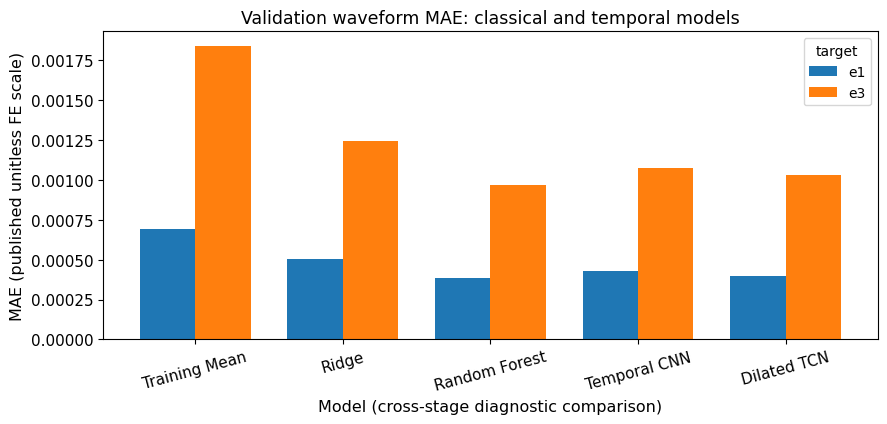

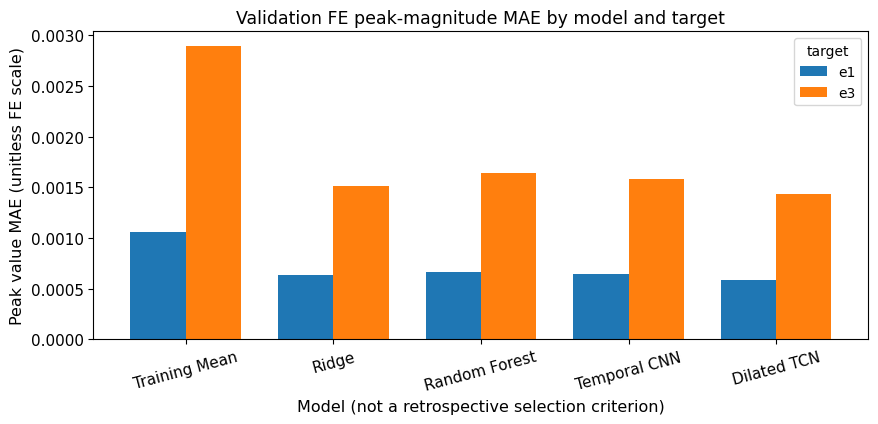

Fixed illustrative Validation trial: subj10:0000


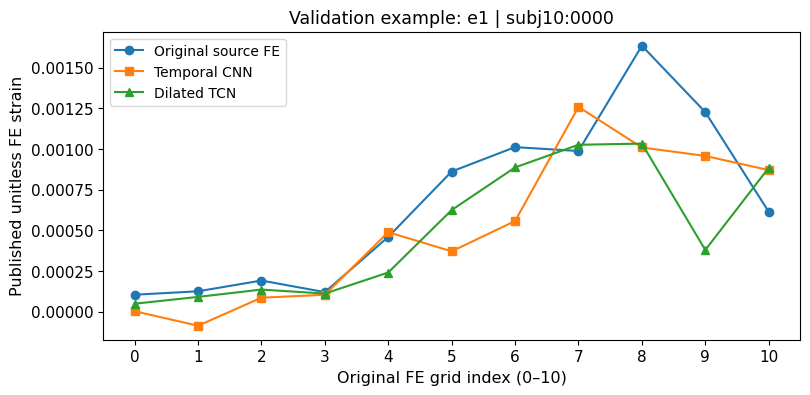

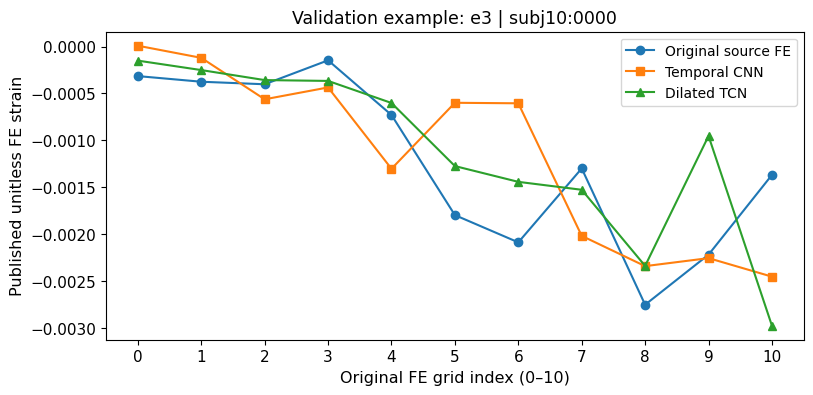

In [10]:
# ================== 09. Scientific Model and Peak Figures ===================
# ---------------------- 1. Paired Target-Level Errors -----------------------
order = ["Training Mean", "Ridge", "Random Forest", *MODEL_NAMES]
curve = comparison.pivot(
    index="model", columns="target", values="mae",
).reindex(order)
fig, ax = plt.subplots(figsize=(10, 4))
curve.plot.bar(ax=ax, width=0.75)
ax.set_title("Validation waveform MAE: classical and temporal models")
ax.set_xlabel("Model (cross-stage diagnostic comparison)")
ax.set_ylabel("MAE (published unitless FE scale)")
ax.tick_params(axis="x", rotation=15)
save_figure(fig, output_dir / "06_validation_waveform_mae_comparison.png")
plt.show()

# ----------------- 2. Peak-Magnitude Errors Are Distinct --------------------
peak = comparison.pivot(
    index="model", columns="target", values="peak_value_mae",
).reindex(order)
fig, ax = plt.subplots(figsize=(10, 4))
peak.plot.bar(ax=ax, width=0.75)
ax.set_title("Validation FE peak-magnitude MAE by model and target")
ax.set_xlabel("Model (not a retrospective selection criterion)")
ax.set_ylabel("Peak value MAE (unitless FE scale)")
ax.tick_params(axis="x", rotation=15)
save_figure(fig, output_dir / "06_validation_peak_mae_comparison.png")
plt.show()

# --------------- 3. Genuine Source-Key-Identified FE Examples ---------------
example_i = int(np.argsort(
    valid_info["local_record_key"].to_numpy()
)[0])
example_key = str(valid_info.iloc[example_i]["local_record_key"])
print("Fixed illustrative Validation trial:", example_key)
for j, target in enumerate(("e1", "e3")):
    fig, ax = plt.subplots(figsize=(9, 4))
    positions = np.arange(11)
    ax.plot(
        positions, y_valid[example_i, :, j],
        marker="o", label="Original source FE",
    )
    for model_name in MODEL_NAMES:
        ax.plot(
            positions,
            validation_predictions[model_name][example_i, :, j],
            marker="s" if model_name == MODEL_NAMES[0] else "^",
            label=model_name,
        )
    ax.set_title(f"Validation example: {target} | {example_key}")
    ax.set_xlabel("Original FE grid index (0–10)")
    ax.set_ylabel("Published unitless FE strain")
    ax.set_xticks(positions)
    ax.legend()
    save_figure(fig, output_dir / f"06_validation_waveform_{target}.png")
    plt.show()


**10. Provenance, Quality Gate and Output Packaging**

**Stage 06 Quality Gate: PASSED.** All 14 public Stage 06 evidence files are committed, including the frozen fold registry, Training loss history, cross-validation summaries, Validation predictions, participant/activity errors, four scientific figures and source-hash provenance. No trained PyTorch weights, locally reconstructed cache or reserved Test performance results were committed. The recorded gate establishes evidence integrity and execution completion, not independent replication or external model validity.


In [11]:
# ==================== 10. Stage 06 Research Quality Gate =====================
# -------------------- 1. Verify Completed Scientific Audit ------------------
assert gate04["stage04_quality_gate"] == "PASSED"
assert gate05["quality_gate"] == "PASSED"
assert source_digest == gate04["canonical_pair_sha256"]
assert set(MODEL_NAMES) == set(cv_summary["model"])
assert len(folds) == 5
assert len(set(train_info["subject_id"])) == 29
assert len(set(valid_info["subject_id"])) == 4
assert len(reserved_ids) == 4
assert not train_ids & valid_ids
assert not train_ids & reserved_ids
assert not valid_ids & reserved_ids
assert val_metrics["selected_from_training_cv"].sum() == 2
assert np.isfinite(val_predictions["predicted"]).all()
assert np.isfinite(cv_summary["subject_balanced_mae"]).all()
assert np.isfinite(history_all["training_loss"]).all()
assert selected_temporal == str(cv_summary.iloc[0]["model"])
expected06 = [
    "06_frozen_training_fold_registry.csv",
    "06_training_loss_history.csv",
    "06_training_cv_fold_metrics.csv",
    "06_training_cv_subject_activity_metrics.csv",
    "06_training_cv_model_summary.csv",
    "06_validation_model_metrics.csv",
    "06_validation_predictions.csv",
    "06_validation_subject_activity_metrics.csv",
    "06_validation_cross_stage_comparison.csv",
    "06_validation_waveform_mae_comparison.png",
    "06_validation_peak_mae_comparison.png",
    "06_validation_waveform_e1.png",
    "06_validation_waveform_e3.png",
    "06_temporal_protocol_and_quality_gate.json",
]
expected_before_gate = [x for x in expected06 if not x.endswith(".json")]
missing = [x for x in expected_before_gate
           if not (output_dir / x).is_file()]
if missing:
    raise FileNotFoundError("Missing current Stage 06 outputs: " +
                            ", ".join(missing))

# ------------------- 2. Persist Actual Provenance and Limits ----------------
source_sha = {
    str(name): hashlib.sha256(path.read_bytes()).hexdigest()
    for name, path in {
        **paths04,
        "stage05_gate": path05,
        "stage05_cv": base_cv_path,
        "stage05_validation": base_val_path,
        "stage05_folds": fold_path,
    }.items()
}
protocol06 = {
    "stage": "06",
    "quality_gate": "PASSED",
    "source_article_id": ARTICLE_ID,
    "source_version": ARTICLE_VERSION,
    "source_archive_sha256": gate04["original_sha256"],
    "canonical_pair_sha256": source_digest,
    "upstream_sha256": source_sha,
    "training_subjects": 29, "training_trials": 1354,
    "validation_subjects": 4, "validation_trials": 192,
    "reserved_test_subjects": 4, "reserved_test_trials": 183,
    "test_model_fitting": False, "test_model_selection": False,
    "test_evaluation": False,
    "prior_validation_not_blind_across_stages": True,
    "selection_dataset": "TRAIN_OOF_ONLY",
    "selection_metric": "subject_balanced_mae",
    "selected_temporal_architecture": selected_temporal,
    "models": list(MODEL_NAMES),
    "train_cv_folds": TRAIN_FOLDS,
    "fixed_epochs": EPOCHS,
    "batch_size": BATCH,
    "learning_rate": LEARNING_RATE,
    "normalised_peak_loss_weight": PEAK_WEIGHT,
    "fit_seed_base": SEED,
    "parameter_counts": parameter_counts,
    "input_contract": "101x42 original source IMU",
    "output_contract": "11x2 original FE source coordinates",
    "native_fe_position_indexing": True,
    "fe_interpolation": False,
    "original_target_unit": "unitless",
    "torch_version": torch.__version__,
    "numpy_version": np.__version__,
    "pandas_version": pd.__version__,
    "run_device": device,
    "clinical_or_external_validation": False,
    "model_weights_committed": False,
}
gate_file = output_dir / "06_temporal_protocol_and_quality_gate.json"
gate_file.write_text(
    json.dumps(protocol06, indent=2) + "\n", encoding="utf-8",
)
assert all((output_dir / name).is_file() for name in expected06)
print("STAGE 06 | DEEP TEMPORAL REGRESSION QUALITY GATE: PASSED")
print("Stage 06 evidence files:", len(expected06))
download_outputs_from_colab(
    folder="biomechanical_load_estimation/output", stage="06",
)


STAGE 06 | DEEP TEMPORAL REGRESSION QUALITY GATE: PASSED
Stage 06 evidence files: 14
------------------------------------------------------------------------
Notebook stage: 06
Files packaged: 14
  + 06_frozen_training_fold_registry.csv
  + 06_temporal_protocol_and_quality_gate.json
  + 06_training_cv_fold_metrics.csv
  + 06_training_cv_model_summary.csv
  + 06_training_cv_subject_activity_metrics.csv
  + 06_training_loss_history.csv
  + 06_validation_cross_stage_comparison.csv
  + 06_validation_model_metrics.csv
  + 06_validation_peak_mae_comparison.png
  + 06_validation_predictions.csv
  + 06_validation_subject_activity_metrics.csv
  + 06_validation_waveform_e1.png
  + 06_validation_waveform_e3.png
  + 06_validation_waveform_mae_comparison.png
Download ZIP from Colab Contents: /content/biomechanical_load_estimation_Stage_06_Outputs.zip
GitHub Commit/Push performed: NO


**11. Scientific Interpretation and Next Research Boundary**

**Completed model comparison.** Dilated TCN was selected over Temporal CNN using Training-only five-fold, participant-disjoint out-of-fold MAE (**0.0008513** versus **0.0009048**). Its Validation MAE was **0.0007151**, compared with **0.0007517** for Temporal CNN, on four participants and 192 trials. All network fits used the predeclared 35-epoch budget and the recorded execution device was CPU.

**Classical versus deep learning.** The Stage 05 Random Forest still had the lowest overall waveform errors: **0.0007950** Training CV and **0.0006771** Validation. Dilated TCN had approximately **5.6% higher Validation waveform error**, so the experiment does **not** demonstrate general superiority of deep learning. Validation had only four participants and was also used for diagnostics in earlier stages; it cannot serve as fully blind evidence for programme-wide decisions.

**Biomechanical trade-off.** Dilated TCN improved peak-magnitude MAE compared with Random Forest for both e1 (**0.0005855** versus **0.0006625**) and e3 (**0.0014333** versus **0.0016423**). However, Random Forest better located the original source-grid peak: respective e1/e3 peak-index errors were **1.417/1.005** for Random Forest and **1.615/1.495** for Dilated TCN. Lower peak-value error therefore does not imply better peak location. The peak-aware loss is a defined training objective, not a complete physics-informed biomechanical model.

**Evidence and limitations.** All 11 code cells executed, and the 14-file Stage 06 Quality Gate reports **PASSED**. Results are based on unitless, model-derived finite-element targets and original 11-point FE grids, not independent clinical measurements. Training used one seed schedule and fixed budgets; repeated-seed stability, independent external validation and clinical or prospective applicability have not been established. All four reserved Test participants remain outside training, selection and scoring.

**Recommended Stage 07 — Robustness, Peak-Error Trade-offs and Research Decision Evidence.** Quantify variation across new, predeclared Training-only seeds, compare Random Forest and temporal models by participant and activity, and assess whether peak-value improvements persist across folds without overfitting the repeatedly inspected Validation set. Only after documenting a frozen decision protocol should a separately approved final Test assessment be considered.
